In [1]:
# Setup

%load_ext autoreload
%autoreload 2

import sys
import json
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.tokenizer import CharTokenizer
from src.model import GPTConfig, MiniGPT
from src.training import train_model, save_checkpoint
from src.evaluation import calculate_perplexity

DATA_DIR = PROJECT_ROOT / "data" / "processed"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Device:", device)

Project root: C:\Users\ASUS\Documents\Projects\Does Shakespeare need Attention
Device: cpu


In [2]:
# Loading

train_data = torch.load(
    DATA_DIR / "train.pt",
    map_location="cpu",
    weights_only=True
)

val_data = torch.load(
    DATA_DIR / "val.pt",
    map_location="cpu",
    weights_only=True
)

test_data = torch.load(
    DATA_DIR / "test.pt",
    map_location="cpu",
    weights_only=True
)

with open(DATA_DIR / "tokenizer.json", "r", encoding="utf-8") as f:
    tokenizer_state = json.load(f)

tokenizer = CharTokenizer.from_dict(tokenizer_state)

print("Vocabulary size:", tokenizer.vocab_size)
print("Train tokens:", len(train_data))
print("Validation tokens:", len(val_data))
print("Test tokens:", len(test_data))

Vocabulary size: 65
Train tokens: 1003854
Validation tokens: 55770
Test tokens: 55770


In [3]:
# Hyperparameters

torch.manual_seed(42)

# Architecture
block_size = 64
n_embd = 128
n_heads = 4
n_layers = 2
ffn_dim = 512
dropout = 0.1

# Training
batch_size = 32
max_iters = 2000
learning_rate = 3e-4
weight_decay = 0.01
eval_interval = 200
eval_iters = 10
grad_clip = 1.0

print("Block size:", block_size)
print("Embedding dimension:", n_embd)
print("Number of heads:", n_heads)
print("Number of layers:", n_layers)
print("Batch size:", batch_size)
print("Maximum iterations:", max_iters)

Block size: 64
Embedding dimension: 128
Number of heads: 4
Number of layers: 2
Batch size: 32
Maximum iterations: 2000


In [4]:
# Initialization

config = GPTConfig(
    vocab_size=tokenizer.vocab_size,
    block_size=block_size,
    n_embd=n_embd,
    n_heads=n_heads,
    n_layers=n_layers,
    ffn_dim=ffn_dim,
    dropout=dropout
)

model = MiniGPT(config).to(device)

num_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(model)
print("\nTotal trainable parameters:", num_parameters)

MiniGPT(
  (token_embedding): Embedding(65, 128)
  (position_embedding): Embedding(64, 128)
  (embedding_dropout): Dropout(p=0.1, inplace=False)
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiHeadSelfAttention(
        (heads): ModuleList(
          (0-3): 4 x CausalSelfAttentionHead(
            (key): Linear(in_features=128, out_features=32, bias=False)
            (query): Linear(in_features=128, out_features=32, bias=False)
            (value): Linear(in_features=128, out_features=32, bias=False)
            (attn_dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (proj): Linear(in_features=128, out_features=128, bias=True)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ffn): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=128, out_f

In [5]:
# Check

from src.dataset import get_batch

x, y = get_batch(
    train_data,
    batch_size=batch_size,
    block_size=block_size,
    device=device
)

logits, loss = model(x, y)

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Logits shape:", logits.shape)
print("Initial loss:", loss.item())

Input shape: torch.Size([32, 64])
Target shape: torch.Size([32, 64])
Logits shape: torch.Size([32, 64, 65])
Initial loss: 4.169787406921387


In [6]:
# Training 

history = train_model(
    model=model,
    train_data=train_data,
    val_data=val_data,
    max_iters=max_iters,
    batch_size=batch_size,
    block_size=block_size,
    learning_rate=learning_rate,
    weight_decay=weight_decay,
    eval_interval=eval_interval,
    eval_iters=eval_iters,
    grad_clip=grad_clip,
    device=device
)

Step     1 | Train Loss: 3.9625 | Val Loss: 3.9630
Step   200 | Train Loss: 2.4766 | Val Loss: 2.4669
Step   400 | Train Loss: 2.3480 | Val Loss: 2.3540
Step   600 | Train Loss: 2.1827 | Val Loss: 2.2008
Step   800 | Train Loss: 2.0874 | Val Loss: 2.1089
Step  1000 | Train Loss: 2.0118 | Val Loss: 2.0701
Step  1200 | Train Loss: 1.9599 | Val Loss: 2.0084
Step  1400 | Train Loss: 1.8865 | Val Loss: 1.9721
Step  1600 | Train Loss: 1.8199 | Val Loss: 1.9110
Step  1800 | Train Loss: 1.7771 | Val Loss: 1.9058
Step  2000 | Train Loss: 1.7526 | Val Loss: 1.8499

Best validation loss: 1.8499


In [7]:
# History

history_df = pd.DataFrame(history)

display(history_df)

history_df.to_csv(
    RESULTS_DIR / "mini_gpt_training_history.csv",
    index=False
)

,step,train_loss,val_loss
0,1,3.962522,3.962966
1,200,2.476608,2.466863
2,400,2.348024,2.353969
3,600,2.182742,2.200757
4,800,2.087364,2.108863
5,1000,2.011750,2.070060
6,1200,1.959941,2.008415
7,1400,1.886467,1.972138
8,1600,1.819896,1.911029
9,1800,1.777059,1.905787


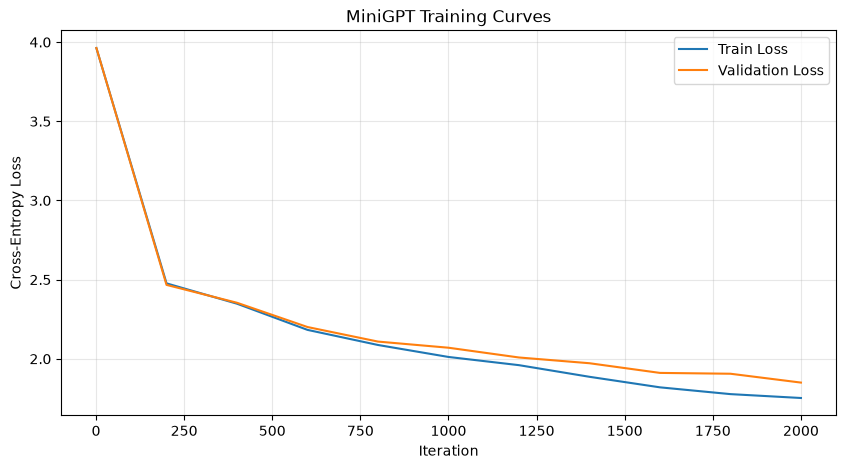

In [8]:
# Visualization

plt.figure(figsize=(10, 5))

plt.plot(
    history_df["step"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["step"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Iteration")
plt.ylabel("Cross-Entropy Loss")
plt.title("MiniGPT Training Curves")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    FIGURES_DIR / "mini_gpt_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Evaluation

@torch.no_grad()
def evaluate_test(model, data, block_size, device):

    was_training = model.training
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for start in range(0, len(data) - 1, block_size):

        end = min(start + block_size, len(data) - 1)

        x = data[start:end]
        y = data[start + 1:end + 1]

        if len(x) == 0:
            continue

        x = x.unsqueeze(0).to(device)
        y = y.unsqueeze(0).to(device)

        _, loss = model(x, y)

        num_tokens = y.numel()

        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    model.train(was_training)

    return total_loss / total_tokens

test_loss = evaluate_test(
    model=model,
    data=test_data,
    block_size=block_size,
    device=device
)

test_perplexity = calculate_perplexity(test_loss)

print("Test Loss:", round(test_loss, 4))
print("Test Perplexity:", round(test_perplexity, 4))

Test Loss: 1.8999
Test Perplexity: 6.6851


In [10]:
# Save

best_row = min(
    history,
    key=lambda row: row["val_loss"]
)

print("Best iteration:", best_row["step"])
print("Best validation loss:", best_row["val_loss"])

checkpoint_path = CHECKPOINT_DIR / "mini_gpt_best.pt"

save_checkpoint(
    path=checkpoint_path,
    model=model,
    tokenizer=tokenizer,
    step=best_row["step"],
    val_loss=best_row["val_loss"]
)

print("Checkpoint saved:", checkpoint_path)

Best iteration: 2000
Best validation loss: 1.8499236941337585
Checkpoint saved: C:\Users\ASUS\Documents\Projects\Does Shakespeare need Attention\checkpoints\mini_gpt_best.pt
Checkpoint saved: C:\Users\ASUS\Documents\Projects\Does Shakespeare need Attention\checkpoints\mini_gpt_best.pt


In [11]:
# Final metrics

metrics = {
    "Model": "MiniGPT",
    "Parameters": num_parameters,
    "Best Iteration": best_row["step"],
    "Best Validation Loss": best_row["val_loss"],
    "Test Loss": test_loss,
    "Test Perplexity": test_perplexity
}

metrics_df = pd.DataFrame([metrics])

display(metrics_df)

metrics_df.to_csv(
    RESULTS_DIR / "mini_gpt_metrics.csv",
    index=False
)

,Model,Parameters,Best Iteration,Best Validation Loss,Test Loss,Test Perplexity
0,MiniGPT,420929,2000,1.849924,1.899879,6.685089
